# LGD de ciclo adverso y los pisos regulatorios

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 a 03 de este tema
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- identificar años de ciclo adverso desde un indicador con `identify_downturn`, y decir que el umbral es un parámetro de política;
- reproducir el ajuste de ciclo adverso por cohortes de C08 con `downturn_add_on`, desde las seis medias por cohorte y sus números de incumplimientos, y compararlo con las filas versionadas;
- juzgar si una estimación de ciclo adverso cubre la pérdida realizada del ciclo adverso con `coverage_shortfall`, leer las pruebas `downturn_coverage` versionadas y decir por qué una prueba en verde y un hallazgo abierto pueden convivir;
- leer los pisos de LGD del marco final de Basilea III con `lgd_floor` y `apply_lgd_floor`, y el piso de EAD con `supervisory_ccf`, `ead_floor` y `apply_ead_floor`;
- decir dónde muerde cada piso, y por qué en C08 y C09 ninguno lo hace.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.lgd_ead import downturn, floors

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 0.9.0
numpy 2.4.6
matplotlib 3.11.2


## Datos

Ocho artefactos versionados. Siete son del caso C08, la LGD de préstamos a pequeñas empresas: las seis variantes por cohorte de incumplimiento `dc-2003-06.json` a `dc-2020-23.json` y el artefacto de modelos `models-dc-2007-08.json`, que guarda la tabla de pisos. El octavo es `data/derived/C09/level-3.json`, el generador de líneas rotativas del caso C09 con nivel de aceleración 3, para el piso de EAD. La LGD es el proxy de castigos del cuaderno 01, así que las cifras de ciclo adverso de abajo son una afirmación sobre el proxy. Los artefactos fueron horneados con motores anteriores al instalado, y la celda siguiente imprime las versiones.

El bloque de ciclo adverso es un hecho del archivo completo, no de una cohorte: la LGD de largo plazo se toma sobre las seis cohortes, así que todas las variantes guardan la misma tabla. La celda carga los artefactos, comprueba esa afirmación comparando dos variantes, e imprime el período que informa el artefacto y cómo se encontró.

In [2]:
# Cargar los artefactos, comprobar que el bloque de ciclo adverso es el mismo en dos variantes e imprimir su período y su enfoque
ROOT = Path("../../..").resolve()
C08, C09 = ROOT / "data" / "derived" / "C08", ROOT / "data" / "derived" / "C09"
COHORTS = ["2003-06", "2007-08", "2009-10", "2011-13", "2014-19", "2020-23"]
cohort = {c: json.loads((C08 / f"dc-{c}.json").read_text(encoding="utf-8")) for c in COHORTS}
models = json.loads((C08 / "models-dc-2007-08.json").read_text(encoding="utf-8"))
level3 = json.loads((C09 / "level-3.json").read_text(encoding="utf-8"))
print("variantes de C08 horneadas con riskvalidation:", sorted({v["provenance"]["riskvalidation_version"] for v in cohort.values()}), "| C09:", level3["provenance"]["riskvalidation_version"], "| instalado:", rv.__version__)
block = cohort["2007-08"]["outputs"]["downturn"]
print("mismo bloque en las variantes 2007-08 y 2009-10:", si_no(block == cohort["2009-10"]["outputs"]["downturn"]))
print("período de ciclo adverso encontrado por el pipeline:", block["period"]["first_year"], "-", block["period"]["last_year"])
print("indicador:", "tasa anual de castigos de la propia cartera SBA 7(a) (castigos del año sobre los préstamos abiertos al 1 de enero)")
print(block["approach"]["es"])

variantes de C08 horneadas con riskvalidation: ['0.6.0'] | C09: 0.6.0 | instalado: 0.9.0
mismo bloque en las variantes 2007-08 y 2009-10: sí
período de ciclo adverso encontrado por el pipeline: 2008 - 2011
indicador: tasa anual de castigos de la propia cartera SBA 7(a) (castigos del año sobre los préstamos abiertos al 1 de enero)
Ajuste por cohortes: la LGD proxy media ponderada por incumplimientos de las cohortes de crisis menos la media de largo plazo de las seis cohortes, con la crisis identificada por la tasa anual de castigos de la cartera SBA 7(a). Una ilustración, no una estimación regulatoria.


## Método

### Paso 1: ¿qué años son de ciclo adverso?

`identify_downturn(years, indicator, threshold, higher_is_worse=True)` del motor marca un año como de ciclo adverso cuando el indicador está estrictamente sobre el umbral (un empate no es ciclo adverso; un indicador faltante produce un error). El motor no elige el umbral: es un **parámetro de política**. El pipeline de C08 lo fija en la media del indicador más una desviación estándar de los años leídos, y usa como indicador la tasa anual de castigos de la propia cartera SBA 7(a), porque ninguna trayectoria macro está entre sus fuentes (el docstring del módulo `downturn` del pipeline). El ciclo adverso es la racha más larga de años consecutivos marcados.

Los valores del indicador no están versionados, solo el período que dieron. La celda siguiente muestra la regla sobre un indicador **inventado** de ocho años, para ver el umbral y las marcas; el período real se lee en el paso 2.

In [3]:
# Aplicar identify_downturn a un indicador inventado de ocho años con un umbral de media más una desviación estándar
years = np.arange(2005, 2013)
rate = np.array([0.010, 0.012, 0.020, 0.050, 0.070, 0.040, 0.020, 0.015])
threshold = rate.mean() + 1.0 * rate.std()
flags = downturn.identify_downturn(years, rate, threshold)
print(f"umbral (media + 1 desviación estándar): {threshold:.4f}")
for year, value, flag in zip(years, rate, flags):
    print(f"{year}  indicador {value:.3f}  año de ciclo adverso: {si_no(flag)}")
print("un valor igual al umbral no es ciclo adverso:", si_no(downturn.identify_downturn(np.array([2020]), np.array([0.05]), 0.05)))

umbral (media + 1 desviación estándar): 0.0498
2005  indicador 0.010  año de ciclo adverso: no
2006  indicador 0.012  año de ciclo adverso: no
2007  indicador 0.020  año de ciclo adverso: no
2008  indicador 0.050  año de ciclo adverso: sí
2009  indicador 0.070  año de ciclo adverso: sí
2010  indicador 0.040  año de ciclo adverso: no
2011  indicador 0.020  año de ciclo adverso: no
2012  indicador 0.015  año de ciclo adverso: no
un valor igual al umbral no es ciclo adverso: ['no']


### Paso 2: el ajuste por cohortes

La LGD de ciclo adverso de C08 es el ajuste por cohortes propio de Contraste, una ilustración y no una estimación regulatoria (los textos de la EBA sobre calibración de ciclo adverso son referencias cruzadas en el motor, y el motor declara que no reclama ningún enfoque regulatorio). Dos números se definen con medias ponderadas por incumplimientos:

$$\text{largo plazo} = \frac{\sum_k n_k\,\overline{LGD}_k}{\sum_k n_k}, \qquad \text{ciclo adverso} = \frac{\sum_{k \in D} n_k\,\overline{LGD}_k}{\sum_{k \in D} n_k}, \qquad \text{ajuste} = \text{ciclo adverso} - \text{largo plazo}$$

donde $k$ recorre las seis cohortes, $\overline{LGD}_k$ es el proxy medio de la cohorte $k$, $n_k$ su número de incumplimientos y $D$ el conjunto de cohortes de ciclo adverso. (Fuente: el docstring de `downturn_add_on`.) La regla del pipeline para $D$ es que una cohorte es de ciclo adverso cuando al menos la mitad de sus años de incumplimiento son años de ciclo adverso.

La celda siguiente lee los años, la media y el número de incumplimientos de cada cohorte desde su propia variante, aplica la regla al período del artefacto (2008 a 2011), llama a `downturn_add_on` y compara el resultado con el ajuste versionado. Se imprime cada intermedio.

In [4]:
# Marcar las cohortes de ciclo adverso con la regla de la mitad de los años, llamar a downturn_add_on y comparar con las filas versionadas
first, last = block["period"]["first_year"], block["period"]["last_year"]
cohort_lgd, weights, mask = [], [], []
print(f"{'cohorte':8s} {'años de incumplimiento':>20s} {'en el período':>16s} {'n':>8s} {'proxy medio':>14s} {'cohorte de ciclo adverso':>24s}")
for c in COHORTS:
    meta = cohort[c]["outputs"]["cohort"]
    span = range(meta["first_year"], meta["last_year"] + 1)
    inside = sum(first <= y <= last for y in span)
    is_down = inside / len(span) >= 0.5
    d = cohort[c]["outputs"]["lgd_distribution"]
    cohort_lgd.append(d["mean"]["value"]); weights.append(d["n"]); mask.append(is_down)
    print(f"{c:8s} {len(span):20d} {inside:16d} {d['n']:8,d} {d['mean']['value']:14.4f} {si_no(is_down)!s:>24s}")

result = downturn.downturn_add_on(np.array(cohort_lgd), np.array(weights, float), np.array(mask))
committed = block["rows"][0]
print()
print(f"LGD de largo plazo: {result.long_run:.6f} | LGD de ciclo adverso: {result.downturn:.6f} | ajuste: {result.add_on:.6f}")
print(f"versionado:           {committed['long_run_lgd']['value']:.6f} | {committed['downturn_lgd']['value']:.6f} | {committed['add_on']:.6f}")
print("cohortes de ciclo adverso versionadas:", [r["cohort_id"] for r in block["rows"]], "| la regla las reproduce:", si_no([c for c, m in zip(COHORTS, mask) if m] == [r["cohort_id"] for r in block["rows"]]))

cohorte  años de incumplimiento    en el período        n    proxy medio cohorte de ciclo adverso
2003-06                     4                0   21,919         0.7081                       no
2007-08                     2                1   25,299         0.8178                       sí
2009-10                     2                2   50,281         0.8221                       sí
2011-13                     3                1   33,673         0.7416                       no
2014-19                     6                0   36,481         0.6631                       no
2020-23                     4                0   13,930         0.7311                       no

LGD de largo plazo: 0.753873 | LGD de ciclo adverso: 0.820644 | ajuste: 0.066770
versionado:           0.753873 | 0.820644 | 0.066770
cohortes de ciclo adverso versionadas: ['2007-08', '2009-10'] | la regla las reproduce: sí


### Paso 3: ¿cubre la estimación la pérdida del ciclo adverso?

Una estimación que debe sostenerse en un ciclo adverso debería ser al menos la pérdida realizada en uno. `coverage_shortfall(estimate, realised)` devuelve si la estimación cubre el valor realizado y por cuánto se queda corta, con una tolerancia de $10^{-12}$: $\text{cubierta} = \text{estimación} \ge \text{realizada} - 10^{-12}$ y $\text{faltante} = \max(0, \text{realizada} - \text{estimación})$. La prueba `downturn_coverage` del motor agrega la vista por préstamo: contrasta si la LGD realizada media del ciclo adverso excede la estimación con un estadístico t unilateral sobre los préstamos de la cohorte, $t = (\overline{y} - \text{estimación}) / (s / \sqrt{n})$, y la colorea con un umbral interno de Contraste (verde cuando el valor p es al menos 0.05, ámbar desde 0.01, rojo bajo eso). Los préstamos no se versionan, así que las filas de la prueba se leen del artefacto, con la versión del motor que las horneó.

La celda aplica `coverage_shortfall` a las dos cohortes de ciclo adverso e imprime las filas de pruebas versionadas y el hallazgo que registró el pipeline.

In [5]:
# Aplicar coverage_shortfall a las dos cohortes de ciclo adverso e imprimir las pruebas downturn_coverage versionadas y el hallazgo
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluado"}
for row in block["rows"]:
    covered, shortfall = downturn.coverage_shortfall(row["downturn_lgd"]["value"], row["crisis_realised_lgd"]["value"])
    print(f"cohorte {row['cohort_id']}: estimación {row['downturn_lgd']['value']:.6f} realizada {row['crisis_realised_lgd']['value']:.6f} -> cubierta {si_no(covered)}, faltante {shortfall:.6f} (versionado: {si_no(row['covered'])}, {row['shortfall']:.6f})")
print()
print("pruebas horneadas con riskvalidation:", cohort["2007-08"]["provenance"]["riskvalidation_version"])
for t in cohort["2007-08"]["tests"]:
    if t["test_id"] == "lgd_ead.downturn_coverage":
        print(f"{t['segment']:17s} t={t['statistic']:7.4f} p={t['p_value']:.4f} faltante={t['metric']:.6f} luz: {LIGHT[t['light']]}")
for f in cohort["2007-08"]["findings"]:
    if f["id"] == "F-downturn-coverage":
        print("hallazgo", f["id"], f["severity"], f["status"], "|", f["title"]["es"])

cohorte 2007-08: estimación 0.820644 realizada 0.817782 -> cubierta sí, faltante 0.000000 (versionado: sí, 0.000000)
cohorte 2009-10: estimación 0.820644 realizada 0.822083 -> cubierta no, faltante 0.001440 (versionado: no, 0.001440)

pruebas horneadas con riskvalidation: 0.6.0
cohort-2007-08    t=-1.4010 p=0.9194 faltante=0.000000 luz: verde
cohort-2009-10    t= 0.9655 p=0.1671 faltante=0.001440 luz: verde
hallazgo F-downturn-coverage S3 open | La LGD de recesión no cubre la pérdida realizada de las cohortes 2009-10


La estimación puntual queda corta respecto de la pérdida realizada de 2009-10 por una cantidad pequeña, así que el pipeline registra un hallazgo abierto de severidad S3; la prueba no puede rechazar que la LGD realizada media esté en o bajo la estimación, así que su luz es verde. Ambas cosas son verdad: existe un faltante en la media, y es demasiado pequeño, frente a la dispersión de 50.281 proxies, para distinguirse estadísticamente de cero. Un validador lee las dos juntas y no las colapsa en un solo veredicto.

### Paso 4: los pisos de LGD

El marco final de Basilea III fija pisos de entrada para la LGD que puede usar un banco de enfoque avanzado, por cartera y garantía (CRE32.16 para corporativo, CRE32.58 y CRE32.59 para minorista; el módulo `floors` del motor transcribe las celdas de la investigación y marca el orden de algunas celdas minoristas como NO VERIFICADO contra el texto del párrafo). `lgd_floor(portfolio, collateral)` devuelve la celda y falla para una combinación sin celda. `apply_lgd_floor(lgd, floor)` devuelve las estimaciones con piso, qué préstamos sube el piso, la media antes y después y el alza, $\max(\text{LGD}, \text{piso})$ préstamo a préstamo.

La celda siguiente imprime la tabla de pisos que lleva el artefacto C08 y comprueba cada celda contra `lgd_floor` del motor, para que una tabla cambiada no pase inadvertida. Luego aplica el piso corporativo sin garantía de 25% a ocho LGD **inventadas**, una mezcla de valores bajos y altos, para mostrar qué hace un piso que muerde.

In [6]:
# Comprobar la tabla de pisos del artefacto contra lgd_floor y aplicar un piso de 25% a ocho LGD inventadas
cells = models["fit"]["floors"]["cells"]
PORTFOLIO = {"corporate": "corporativo", "retail": "minorista"}
COLLATERAL = {"unsecured": "sin garantía", "financial": "financiera", "receivables": "cuentas por cobrar", "real-estate": "inmobiliaria",
              "other-physical": "otra física", "mortgage": "hipotecaria", "qrre": "renovable calificada (QRRE)"}
print("régimen:", "Basilea III final", "(" + models["fit"]["floors"]["regime"] + ")")
agree = 0
for cell in cells:
    engine_floor = floors.lgd_floor(cell["portfolio"], cell["collateral"])
    agree += engine_floor == cell["floor"]
    print(f"{PORTFOLIO[cell['portfolio']]:12s} {COLLATERAL[cell['collateral']]:24s} piso {cell['floor']:.2f} motor {engine_floor:.2f} ({cell['reference'].replace(' to ', ' a ')})")
print(f"celdas iguales a las del motor: {agree} de {len(cells)}")

invented = np.array([0.03, 0.08, 0.15, 0.22, 0.30, 0.45, 0.60, 0.90])
bite = floors.apply_lgd_floor(invented, floors.lgd_floor("corporate", "unsecured"))
print()
print("LGD inventadas:", invented)
print("tras el piso:   ", bite.applied)
print(f"el piso muerde en {int(bite.binding.sum())} de {invented.size} (parte {bite.share_binding:.3f}) | media antes {bite.mean_before:.4f} | media después {bite.mean_after:.4f} | alza {bite.uplift:.4f}")

régimen: Basilea III final (basel-iii-final)
corporativo  sin garantía             piso 0.25 motor 0.25 (CRE32.16)
corporativo  financiera               piso 0.00 motor 0.00 (CRE32.16)
corporativo  cuentas por cobrar       piso 0.10 motor 0.10 (CRE32.16)
corporativo  inmobiliaria             piso 0.10 motor 0.10 (CRE32.16)
corporativo  otra física              piso 0.15 motor 0.15 (CRE32.16)
minorista    hipotecaria              piso 0.05 motor 0.05 (CRE32.58 a CRE32.59)
minorista    renovable calificada (QRRE) piso 0.50 motor 0.50 (CRE32.58 a CRE32.59)
minorista    sin garantía             piso 0.30 motor 0.30 (CRE32.58 a CRE32.59)
minorista    financiera               piso 0.00 motor 0.00 (CRE32.58 a CRE32.59)
minorista    cuentas por cobrar       piso 0.10 motor 0.10 (CRE32.58 a CRE32.59)
minorista    inmobiliaria             piso 0.10 motor 0.10 (CRE32.58 a CRE32.59)
minorista    otra física              piso 0.15 motor 0.15 (CRE32.58 a CRE32.59)
celdas iguales a las del motor: 12 

### Paso 5: dónde muerde el piso de LGD en C08

El artefacto C08 aplica los pisos a las predicciones del logit fraccional de cada cohorte, por segmento (`outputs.floors_bite`). El archivo SBA no tiene un campo de garantía, así que el pipeline infiere la garantía desde el plazo y el carácter rotativo (líneas y préstamos de hasta 7 años como sin garantía, de 7 a 20 años como otra física, de 20 años o más como inmobiliaria), como dice la nota del propio artefacto; el piso de cada segmento se sigue de ahí. El efecto es el alza media. La celda imprime las tablas de 2007-08 y 2009-10 y dibuja la LGD predicha media de cada segmento frente a su piso.

Pisos del dossier 01 A.5 aplicados a las predicciones de L2-fractional-logit de la cohorte, por segmento; el archivo SBA no tiene campo de garantía, de modo que la garantía se infiere del plazo y de si es línea rotativa (líneas y préstamos de hasta 7 años como sin garantía, de 7 a 20 años como otra física, de 20 años o más como inmobiliaria). El efecto es el alza media.

cohorte 2007-08
  sme-revolver         corporate-unsecured        piso 0.25  n= 7,864  media antes 0.8903  parte que muerde 0.000  alza 0.0000
  sme-term-up-to-84    corporate-unsecured        piso 0.25  n=14,454  media antes 0.7254  parte que muerde 0.000  alza 0.0000
  sme-term-85-239      corporate-other-physical   piso 0.15  n= 2,739  media antes 0.6270  parte que muerde 0.000  alza 0.0000
  sme-term-240-plus    corporate-real-estate      piso 0.10  n=   242  media antes 0.6017  parte que muerde 0.000  alza 0.0000
cohorte 2009-10
  sme-revolver         corporate-unsecured        piso 0.25  n=20,945  media antes 0.8

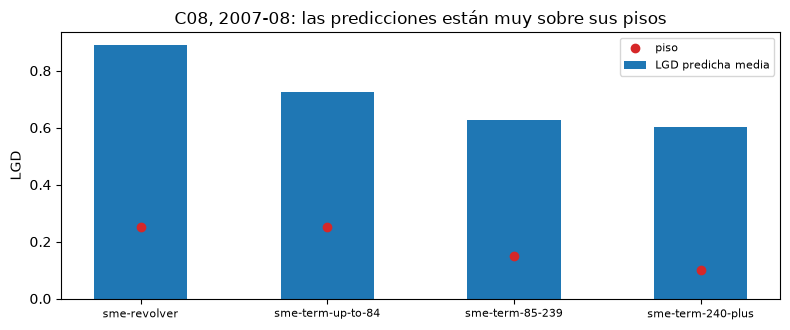

In [7]:
# Imprimir las tablas floors_bite versionadas de dos cohortes y dibujar la predicción media de cada segmento frente a su piso
print(cohort["2007-08"]["outputs"]["floors_bite"]["note"]["es"])
print()
for c in ("2007-08", "2009-10"):
    rows = cohort[c]["outputs"]["floors_bite"]["rows"]
    print(f"cohorte {c}")
    for r in rows:
        print(f"  {r['segment_id']:20s} {r['floor_id']:26s} piso {r['floor']:.2f}  n={r['n']:6,d}  media antes {r['mean_before']['value']:.4f}  parte que muerde {r['share_binding']:.3f}  alza {r['uplift']:.4f}")

rows = cohort["2007-08"]["outputs"]["floors_bite"]["rows"]
fig, ax = plt.subplots(figsize=(8, 3.4))
positions = np.arange(len(rows))
ax.bar(positions, [r["mean_before"]["value"] for r in rows], width=0.5, color="tab:blue", label="LGD predicha media")
ax.scatter(positions, [r["floor"] for r in rows], color="tab:red", zorder=3, label="piso")
ax.set_xticks(positions)
ax.set_xticklabels([r["segment_id"] for r in rows], fontsize=8)
ax.set_ylabel("LGD")
ax.set_title("C08, 2007-08: las predicciones están muy sobre sus pisos")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Paso 6: el piso de EAD

El piso de EAD del mismo marco (CRE32.36 para corporativo, CRE32.64 para minorista) dice "el monto en balance más 50% de la exposición fuera de balance usando el CCF estandarizado". La fórmula del motor es $\text{piso} = E + s\,c\,\max(L - E, 0)$ con $s$ la parte fuera de balance (0.5) y $c$ el factor de conversión supervisor de la clase de línea, que devuelve `supervisory_ccf(item)` (por ejemplo 0.4 para compromisos, CRE20.98, y 0.1 para líneas cancelables sin condiciones, CRE20.100). La lectura de que el 50% se aplica a la exposición fuera de balance ponderada por el CCF sigue la redacción de la investigación y el motor la marca NO VERIFICADA contra el texto del párrafo. Una línea sobregirada no tiene monto fuera de balance, así que su piso es su monto utilizado. `apply_ead_floor(ead, floor)` toma el máximo elemento a elemento.

La celda lista los cinco factores supervisores, aplica el piso a tres líneas **inventadas** (una de ellas sobregirada), y luego lee lo que informa el artefacto C09 para la misma regla sobre las líneas de su generador.

In [8]:
# Listar los CCF supervisores, aplicar el piso de EAD a tres líneas inventadas y leer el bloque de piso del artefacto C09
ITEM = {"direct-credit-substitutes": "sustitutos directos de crédito", "nifs-rufs-transaction-related-contingents": "NIF, RUF y contingentes ligados a transacciones",
        "commitments": "compromisos", "short-term-self-liquidating-trade-letters-of-credit": "cartas de crédito comerciales de corto plazo autoliquidables",
        "unconditionally-cancellable": "cancelables sin condiciones"}
for item in floors.SUPERVISORY_CCF:
    print(f"{ITEM[item]:75s} {floors.supervisory_ccf(item):.1f}")
drawn = np.array([20.0, 60.0, 110.0])
limit = np.array([100.0, 100.0, 100.0])
sa_ccf = np.array([floors.supervisory_ccf("commitments")] * 3)
floor_ead = floors.ead_floor(drawn, limit, sa_ccf)
estimate = np.array([40.0, 70.0, 105.0])
bite_ead = floors.apply_ead_floor(estimate, floor_ead)
print()
print("utilizado:", drawn, "| límite:", limit)
print("piso de EAD:", floor_ead, "| estimaciones de EAD inventadas:", estimate, "| tras el piso:", bite_ead.applied)
print(f"el piso muerde en {int(bite_ead.binding.sum())} de {estimate.size}")
print()
eadf = level3["outputs"]["ead_floor"]
print("C09:", "regla: monto en balance + 50% de la exposición fuera de balance al CCF estandarizado (CRE32.36, CRE32.64)")
for r in eadf["rows"]:
    print(f"  {ITEM[r['facility_class']]:36s} CCF {r['sa_ccf']:.1f} ({r['reference']}) n={r['n']:,} parte que muerde {r['share_binding']:.3f} EAD media antes y después {r['mean_ead_before']:.2f} {r['mean_ead_after']:.2f}")

sustitutos directos de crédito                                              1.0
NIF, RUF y contingentes ligados a transacciones                             0.5
compromisos                                                                 0.4
cartas de crédito comerciales de corto plazo autoliquidables                0.2
cancelables sin condiciones                                                 0.1

utilizado: [ 20.  60. 110.] | límite: [100. 100. 100.]
piso de EAD: [ 36.  68. 110.] | estimaciones de EAD inventadas: [ 40.  70. 105.] | tras el piso: [ 40.  70. 110.]
el piso muerde en 1 de 3

C09: regla: monto en balance + 50% de la exposición fuera de balance al CCF estandarizado (CRE32.36, CRE32.64)
  cancelables sin condiciones          CCF 0.1 (CRE20.100) n=38,817 parte que muerde 0.000 EAD media antes y después 5183.05 5183.05
  compromisos                          CCF 0.4 (CRE20.98) n=38,817 parte que muerde 0.000 EAD media antes y después 5183.05 5183.05


## Resultados

- **El umbral es una decisión de política.** En el indicador inventado el umbral (media más una desviación estándar) es 0,0498, y solo 2008 y 2009 quedan sobre él; un valor exactamente en el umbral no se marca.
- **El ajuste se reproduce.** Con el período real de 2008 a 2011, la regla de la mitad de los años elige las cohortes 2007-08 (uno de sus dos años dentro del período) y 2009-10 (ambos). `downturn_add_on` da una LGD de largo plazo de 0,753873, una LGD de ciclo adverso de 0,820644 y un ajuste de 0,066770, iguales a las filas versionadas con seis decimales. El ajuste es una diferencia de dos medias de un proxy, no una estimación regulatoria.
- **Una prueba en verde y un hallazgo abierto conviven.** La estimación cubre la pérdida realizada de 2007-08 y se queda corta en 2009-10 por 0,001440. Las pruebas `downturn_coverage` están en verde en ambas (valores p 0,9194 y 0,1671), y el pipeline mantiene el hallazgo abierto con severidad S3: el faltante existe en la media y es pequeño frente a la dispersión de 50.281 proxies.
- **Los pisos son una tabla comprobada.** Las 12 celdas de la tabla de pisos del artefacto son iguales a `lgd_floor` del motor. Sobre ocho LGD inventadas el piso de 25% muerde en cuatro y sube la media de 0,3412 a 0,4062, un alza de 0,0650.
- **En C08 y C09 ningún piso muerde.** La LGD predicha media de los segmentos de C08 va de 0,6017 a 0,8903 en 2007-08 frente a pisos de 0,10 a 0,25, y cada segmento muestra una parte que muerde de 0,000 en 2007-08 y en 2009-10. El piso de EAD de C09 no muerde en ninguna de las 38.817 líneas en incumplimiento con ninguno de los dos factores supervisores. El ejemplo inventado de EAD sí muerde en una línea de tres, la sobregirada, cuyo piso es su monto utilizado de 110.

Lo que el cuaderno no hace: no estima una LGD de ciclo adverso para un regulador ni valida un piso. El proxy tiene LGD altas por construcción, así que un piso que importa en una cartera hipotecaria de LGD baja no importa aquí; los ejemplos inventados existen para mostrar la aritmética donde sí importa. El cuaderno siguiente mide el sesgo de los estimadores de CCF contra la verdad conocida de C09.

## Resumen

- `identify_downturn` marca los años cuyo indicador está estrictamente sobre un umbral que es un parámetro de política; el pipeline de C08 toma la media más una desviación estándar de la propia tasa anual de castigos de la cartera y la racha más larga de años marcados.
- El ajuste por cohortes es una diferencia de medias ponderadas por incumplimientos, `downturn_add_on`; reproduce las filas versionadas una vez que la regla de la mitad de los años elige las cohortes. Es una ilustración, no una estimación regulatoria.
- La cobertura se juzga sobre la estimación puntual (`coverage_shortfall`) y sobre los préstamos (`downturn_coverage`); las dos pueden diferir, y ambas se informan.
- Los pisos de LGD son una tabla por cartera y garantía (`lgd_floor`, `apply_lgd_floor`) y el piso de EAD es el monto utilizado más la mitad del monto no utilizado ponderado por el CCF (`ead_floor`, `apply_ead_floor`). En C08 y C09 ningún piso muerde.

**Qué probar a continuación.** Baja las estimaciones de EAD inventadas del paso 6 y mira cómo el piso empieza a morder; aplica el piso minorista hipotecario de 5% a un conjunto de LGD bajas. Luego sigue con el cuaderno 05, que mide cómo la elección de la fecha de referencia sesga el CCF.

## Referencias

- BCBS, Basel Framework, CRE32 (enfoque de calificaciones internas; los pisos de entrada de LGD, CRE32.16 y CRE32.58 a CRE32.59, y el piso de EAD, CRE32.36 y CRE32.64, como los transcribe el módulo `floors` del motor). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- BCBS (2017), Basel III: Finalising post-crisis reforms (d424). https://www.bis.org/bcbs/publ/d424.htm
- EBA/RTS/2018/04 y EBA/GL/2019/03 sobre la estimación de ciclo adverso: solo referencias cruzadas en el módulo `downturn` del motor, que declara que el ajuste es el cohortal de Contraste y no reclama ningún enfoque regulatorio.
- La documentación del propio motor: `riskvalidation.lgd_ead.downturn` y `riskvalidation.lgd_ead.floors` (versión 0.8.1).
- Este repositorio: `docs/design/SDD.md` (casos C08 y C09), `data-pipeline/pipeline/cases/c08/downturn.py` (la regla de las cohortes de ciclo adverso) y `data/derived/C08/`, `data/derived/C09/level-3.json`.